# 비언어 소리 7클래스 분류 학습 (Colab)

`windows_v1.npz`의 1.4초 조각 → 학습 때 1초를 꺼내 증강 → `features.py`로 `[3,64,64]` → ResNet-18 / MobileNetV2 전이학습 → ONNX.

**준비 (한 번만):** Google Drive `MyDrive/ondevice/` 폴더에 아래 4개 파일을 올린다.

| 파일 | 맥에서 위치 |
|---|---|
| `windows_v1.npz` (795 MB) | `프로젝트/sound_data/windows/` |
| `windows_v1.csv` | `프로젝트/sound_data/windows/` |
| `splits_v1.csv` | `프로젝트/sound_data/windows/` |
| `features.py` | `프로젝트/train/` |

**실행:** 런타임 → 런타임 유형 변경 → T4 GPU → 모두 실행.
결과(`best.pt`, `last.pt`, `.onnx`, 혼동 행렬, 점수)는 `MyDrive/ondevice/runs/<모델>_v1/`에 저장된다.
Colab이 끊기면 다시 모두 실행하면 `last.pt`에서 이어서 학습한다.

In [1]:
# 1. 설정: 모델을 바꿀 때는 MODEL만 바꾼다
MODEL = "resnet18"            # "resnet18" 또는 "mobilenet_v2"
VERSION = "v1"
EPOCHS, PATIENCE, BATCH = 40, 6, 128       # 검증 macro-F1이 6 epoch 동안 안 오르면 멈춤
LR = 3e-4 if MODEL == "resnet18" else 5e-4
PER_CLASS = 1000              # 1 epoch에 클래스마다 뽑는 개수 (총 7,000개)
DRIVE = "/content/drive/MyDrive/ondevice"
DATA = "/content/data"
CLASSES = ["whistle_up", "whistle_down", "tongue_click2", "shh", "clap2", "speech", "background"]

In [5]:
# 2. Drive 연결, 데이터를 Colab 로컬 디스크로 복사 (Drive에서 바로 읽으면 느림)
from google.colab import drive
drive.mount("/content/drive")
import os, shutil, sys
os.makedirs(DATA, exist_ok=True)
for f in [f"windows_{VERSION}.npz", f"windows_{VERSION}.csv", f"splits_{VERSION}.csv", "features.py"]:
    if not os.path.exists(f"{DATA}/{f}"):
        shutil.copy(f"{DRIVE}/{f}", DATA)
sys.path.insert(0, DATA)
RUN = f"{DRIVE}/runs/{MODEL}_{VERSION}"
os.makedirs(RUN, exist_ok=True)
!nvidia-smi -L

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU 0: Tesla T4 (UUID: GPU-a9c4f9c5-6015-2ae9-c04c-86fb1e31560b)


In [6]:
# 3. 데이터 읽기
import numpy as np, pandas as pd
import features as F                      # 보드와 같은 전처리 코드

SR = 16000
audio = np.load(f"{DATA}/windows_{VERSION}.npz")["audio"]          # int16 [N, 22400] = 1.4초 조각
win = pd.read_csv(f"{DATA}/windows_{VERSION}.csv", index_col="idx")
win["split"] = pd.read_csv(f"{DATA}/splits_{VERSION}.csv", index_col="idx").split
Y = win.cls.map(CLASSES.index).to_numpy()
ON, OFF = win.on.to_numpy(), win.off.to_numpy()   # 조각 안에서 소리가 있는 구간(초)
idx = {s: win.index[win.split == s].to_numpy() for s in ["train", "val", "test"]}
# 소음 섞기에 쓸 배경 조각 (학습용 배경만 써서 검증·평가 소리가 새지 않게)
noise_pool = win.index[(win.split == "train") & (win.cls == "background")].to_numpy()
print(pd.crosstab(win.cls, win.split).reindex(CLASSES)[["train", "val", "test"]])

split          train   val  test
cls                             
whistle_up        70    15    15
whistle_down      70    15    15
tongue_click2     70    15    15
shh              177    38    38
clap2             70    15    15
speech          6276  1338  1355
background      5572  1194  1194


In [7]:
# 4. 1초 꺼내기 + 증강 (wav 단계) -> features.py -> Mel 대역 가리기 (이미지 단계)
# 시간 반전·음 높이 변경은 쓰지 않는다: 휘파람 ↗/↘의 방향이 바뀌기 때문
rng = np.random.default_rng(0)
SHIFT = int(0.4 * SR)                     # 1.4초 조각에서 1초를 꺼낼 수 있는 여유 (±0.2초)

def pick_start(i, train):
    # 평가 때는 가운데. 명령 소리는 make_windows.py가 조각 가운데에 놓았다.
    if not train:
        return SHIFT // 2
    # 학습 때는 소리 [on, off]가 1초 안에 다 들어가는 범위에서 무작위 (시간 이동 증강)
    lo, hi = max(0.0, OFF[i] - 1.0), min(0.4, ON[i])
    if lo > hi:                           # 소리가 1초보다 길면(배경, 말소리) 아무 위치나
        lo, hi = 0.0, 0.4
    return int(rng.uniform(lo, hi) * SR)

def add_noise(x, i, s):
    # 배경 소음을 SNR 0~20 dB로 섞는다. 신호 세기는 소리가 있는 구간에서 잰다
    # (짧은 혀 차기는 1초 전체 평균으로 재면 너무 작게 잡혀 소음에 묻힌다)
    j = rng.choice(noise_pool)
    k = rng.integers(SHIFT + 1)
    n = audio[j, k:k + SR].astype(np.float32) / 32768
    a, b = max(int(ON[i] * SR) - s, 0), min(int(OFF[i] * SR) - s, SR)
    sig = x[a:b] if b - a >= 160 else x
    ps, pn = np.mean(sig ** 2), np.mean(n ** 2)
    if pn < 1e-10 or ps < 1e-10:
        return x
    snr = rng.uniform(0, 20)
    return x + n * np.sqrt(ps / (pn * 10 ** (snr / 10)))

def mask_bands(img):
    # Mel 대역 가리기: 연속 1~8대역을 '소리 없음'으로 (dB 채널 0, 변화량 채널 128 = 변화 0)
    w = int(rng.integers(1, 9)); f0 = int(rng.integers(0, 64 - w + 1))
    img = img.copy()
    img[0, f0:f0 + w] = 0
    img[1:, f0:f0 + w] = 128
    return img

def make_input(i, train):
    s = pick_start(i, train)
    x = audio[i, s:s + SR].astype(np.float32) / 32768
    if train:
        x = x * 10 ** (rng.uniform(-12, 6) / 20)          # 음량 −12 ~ +6 dB
        if rng.random() < 0.5:
            x = add_noise(x, i, s)
        x = np.clip(x, -1, 1)
    img = F.features(x)                                    # uint8 [3, 64, 64]
    if train and rng.random() < 0.5:
        img = mask_bands(img)
    return img

In [8]:
# 5. DataLoader: 클래스마다 같은 확률로 뽑는다 (배경·말소리는 수천 개, 명령은 70개라 그대로 두면 배경만 맞히는 모델이 됨)
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

class TrainSet(Dataset):
    def __len__(self):
        return len(idx["train"])
    def __getitem__(self, k):
        i = idx["train"][k]
        return torch.from_numpy(make_input(i, True)), int(Y[i])

def seed_worker(_):
    # DataLoader 작업 프로세스마다 다른 난수를 쓰게 한다 (안 하면 모든 프로세스가 같은 증강을 반복)
    global rng
    rng = np.random.default_rng(torch.initial_seed() % 2**32)

ytr = Y[idx["train"]]
weights = 1.0 / np.bincount(ytr, minlength=len(CLASSES))[ytr]
sampler = WeightedRandomSampler(weights, num_samples=PER_CLASS * len(CLASSES), replacement=True)
train_loader = DataLoader(TrainSet(), batch_size=BATCH, sampler=sampler, num_workers=2,
                          worker_init_fn=seed_worker, pin_memory=True, drop_last=True)

# 검증·평가는 증강 없이 한 번만 변환해 둔다
def fixed_set(ids):
    return torch.from_numpy(np.stack([make_input(i, False) for i in ids])), Y[ids]
Xva, Yva = fixed_set(idx["val"])
Xte, Yte = fixed_set(idx["test"])
print("검증", Xva.shape, "평가", Xte.shape)

검증 torch.Size([2630, 3, 64, 64]) 평가 torch.Size([2647, 3, 64, 64])


In [9]:
# 6. 모델: ImageNet 사전학습 + 마지막 층만 7클래스로 교체, 입력 정규화는 모델 안에
import torch.nn as nn, torchvision

class Net(nn.Module):
    # 입력: [N, 3, 64, 64], 값 0~255 (features.py 출력 그대로).
    # 정규화를 모델 안에 넣어서 보드에서는 uint8 이미지를 그대로 넣으면 된다.
    def __init__(self, name):
        super().__init__()
        if name == "resnet18":
            m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
            m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
        else:
            m = torchvision.models.mobilenet_v2(weights="IMAGENET1K_V1")
            m.classifier[1] = nn.Linear(m.last_channel, len(CLASSES))
        self.m = m
    def forward(self, x):
        return self.m(x / 127.5 - 1.0)

torch.manual_seed(0)
model = Net(MODEL).cuda()
print(MODEL, f"파라미터 {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 146MB/s]


resnet18 파라미터 11.18 M


In [10]:
# 7. 학습 (매 epoch last.pt 저장, 검증 macro-F1이 가장 높을 때 best.pt 저장)
import time
from sklearn.metrics import f1_score

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
crit = nn.CrossEntropyLoss(label_smoothing=0.05)       # 과신을 줄여 확률 0.7 기준이 의미 있게
scaler = torch.amp.GradScaler()
start, best, bad, hist = 0, -1.0, 0, []

if os.path.exists(f"{RUN}/last.pt"):                    # Colab이 끊겼다가 다시 돌릴 때 이어서
    ck = torch.load(f"{RUN}/last.pt", weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    start, best, bad, hist = ck["epoch"] + 1, ck["best"], ck["bad"], ck["hist"]
    print(f"{start} epoch부터 이어서 (지금까지 최고 {best:.3f})")

def predict(X):
    model.eval()
    out = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for k in range(0, len(X), 512):
            out.append(model(X[k:k + 512].cuda().float()).float().softmax(1).cpu())
    return torch.cat(out).numpy()

for ep in range(start, EPOCHS):
    if bad >= PATIENCE:
        break
    model.train()
    t0 = tl = time.time(); t_wait = 0.0; losses = []
    for x, y in train_loader:
        t_wait += time.time() - tl                       # 전처리(CPU)를 기다린 시간
        x, y = x.cuda(non_blocking=True).float(), y.cuda(non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = crit(model(x), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        losses.append(loss.item()); tl = time.time()
    sched.step()
    f1 = f1_score(Yva, predict(Xva).argmax(1), average="macro")
    sec = time.time() - t0
    hist.append(dict(epoch=ep + 1, loss=float(np.mean(losses)), val_f1=float(f1), sec=sec, wait=t_wait))
    if f1 > best:
        best, bad = f1, 0
        torch.save(model.state_dict(), f"{RUN}/best.pt")
    else:
        bad += 1
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    epoch=ep, best=best, bad=bad, hist=hist), f"{RUN}/last.pt")
    print(f"epoch {ep + 1:2d}  loss {np.mean(losses):.3f}  val macro-F1 {f1:.3f}  "
          f"{sec:.0f}초 (전처리 대기 {t_wait:.0f}초){'  *' if bad == 0 else ''}")
print(f"끝. 최고 검증 macro-F1 {best:.3f}")

epoch  1  loss 0.562  val macro-F1 0.818  35초 (전처리 대기 28초)  *
epoch  2  loss 0.350  val macro-F1 0.835  23초 (전처리 대기 19초)  *
epoch  3  loss 0.329  val macro-F1 0.847  30초 (전처리 대기 26초)  *
epoch  4  loss 0.314  val macro-F1 0.911  29초 (전처리 대기 25초)  *
epoch  5  loss 0.311  val macro-F1 0.857  28초 (전처리 대기 25초)
epoch  6  loss 0.303  val macro-F1 0.861  30초 (전처리 대기 26초)
epoch  7  loss 0.294  val macro-F1 0.925  30초 (전처리 대기 26초)  *
epoch  8  loss 0.302  val macro-F1 0.887  29초 (전처리 대기 25초)
epoch  9  loss 0.294  val macro-F1 0.950  30초 (전처리 대기 26초)  *
epoch 10  loss 0.292  val macro-F1 0.935  30초 (전처리 대기 26초)
epoch 11  loss 0.287  val macro-F1 0.903  29초 (전처리 대기 25초)
epoch 12  loss 0.285  val macro-F1 0.920  30초 (전처리 대기 26초)
epoch 13  loss 0.285  val macro-F1 0.911  30초 (전처리 대기 26초)
epoch 14  loss 0.285  val macro-F1 0.898  26초 (전처리 대기 22초)
epoch 15  loss 0.289  val macro-F1 0.926  25초 (전처리 대기 21초)
끝. 최고 검증 macro-F1 0.950


               precision    recall  f1-score   support

   whistle_up      1.000     1.000     1.000        15
 whistle_down      0.938     1.000     0.968        15
tongue_click2      0.750     1.000     0.857        15
          shh      0.844     1.000     0.916        38
        clap2      0.882     1.000     0.938        15
       speech      0.988     0.999     0.994      1355
   background      0.999     0.974     0.986      1194

     accuracy                          0.988      2647
    macro avg      0.915     0.996     0.951      2647
 weighted avg      0.989     0.988     0.988      2647



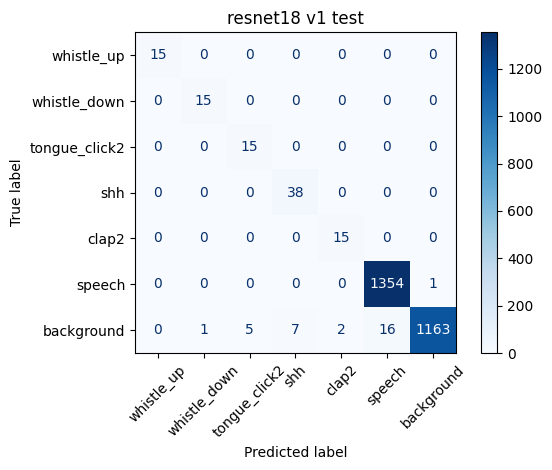

말소리·배경이 명령으로 분류된 비율: 0.59%


In [11]:
# 8. 평가 데이터로 최종 점수 (best.pt)
import json, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model.load_state_dict(torch.load(f"{RUN}/best.pt"))
P = predict(Xte); pred = P.argmax(1)
print(classification_report(Yte, pred, labels=list(range(len(CLASSES))), target_names=CLASSES,
                            digits=3, zero_division=0))

cm = confusion_matrix(Yte, pred, labels=range(len(CLASSES)))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(xticks_rotation=45, cmap="Blues")
plt.title(f"{MODEL} {VERSION} test"); plt.tight_layout(); plt.savefig(f"{RUN}/confusion_test.png", dpi=120); plt.show()

ignore = np.isin(Yte, [5, 6])                            # 말소리·배경
false_cmd = float(((pred < 5) & ignore).sum() / ignore.sum())
print(f"말소리·배경이 명령으로 분류된 비율: {false_cmd:.2%}")
metrics = dict(model=MODEL, version=VERSION, best_val_f1=best,
               test_f1=float(f1_score(Yte, pred, average="macro")),
               test_recall={c: float(cm[k, k] / max(cm[k].sum(), 1)) for k, c in enumerate(CLASSES)},
               false_command_rate=false_cmd, hist=hist)
json.dump(metrics, open(f"{RUN}/metrics.json", "w"), ensure_ascii=False, indent=1)

In [12]:
# 9. ONNX 내보내기: 입력 이름 images, [1,3,64,64] 고정, opset 12. 출력은 logits (확률은 보드에서 softmax)
!pip -q install onnx onnxruntime
import onnxruntime as ort

cpu_model = Net(MODEL).eval()
cpu_model.load_state_dict(torch.load(f"{RUN}/best.pt", map_location="cpu"))
onnx_path = f"{RUN}/{MODEL}_{VERSION}.onnx"
torch.onnx.export(cpu_model, torch.zeros(1, 3, 64, 64), onnx_path, input_names=["images"],
                  output_names=["logits"], opset_version=12, dynamo=False)

# PyTorch와 onnxruntime 출력 비교 (평가 데이터 전체, 1장씩)
sess = ort.InferenceSession(onnx_path)
diff, same = 0.0, 0
with torch.no_grad():
    for k in range(len(Xte)):
        x = Xte[k:k + 1].float()
        a = cpu_model(x).numpy()
        b = sess.run(None, {"images": x.numpy()})[0]
        diff = max(diff, float(np.abs(a - b).max()))
        same += int(a.argmax() == b.argmax())
print(f"최대 오차 {diff:.2e} (목표 1e-4 이하), 예측 일치 {same}/{len(Xte)}")
print("저장:", onnx_path)

/tmp/ipykernel_2317/3651411701.py:8: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(cpu_model, torch.zeros(1, 3, 64, 64), onnx_path, input_names=["images"],


최대 오차 4.65e-06 (목표 1e-4 이하), 예측 일치 2647/2647
저장: /content/drive/MyDrive/ondevice/runs/resnet18_v1/resnet18_v1.onnx
